# 🛒 Limpieza de datos y Feature Engineering — Pedidos de una tienda online

**Práctica Integradora · Talendig · Mes 4 · Data Science para IA**

Pipeline completo, de principio a fin, sobre un registro de pedidos de una tienda en línea con clientes en distintos sectores de Santo Domingo: carga y exploración, diagnóstico de nulos, limpieza, creación de nuevas variables y exportación del dataset final.

## Contenido
1. [Configuración e imports](#1.-Configuración-e-imports)
2. [Carga y exploración inicial](#2.-Carga-y-exploración-inicial)
3. [Diagnóstico de valores nulos](#3.-Diagnóstico-de-valores-nulos)
4. [Estrategia de limpieza de nulos](#4.-Estrategia-de-limpieza-de-nulos)
5. [Eliminación de duplicados](#5.-Eliminación-de-duplicados)
6. [Corrección de tipos de datos](#6.-Corrección-de-tipos-de-datos)
7. [Feature engineering](#7.-Feature-engineering)
8. [Mediana vs. promedio con datos reales](#8.-Mediana-vs.-promedio-con-datos-reales)
9. [Visualizaciones](#9.-Visualizaciones)
10. [Resumen final y exportación](#10.-Resumen-final-y-exportación)
11. [Conclusiones](#11.-Conclusiones)

## Diccionario de datos

| Columna | Significado |
|---|---|
| `PedidoID` | Identificador único del pedido |
| `Cliente` | Nombre completo del cliente |
| `DireccionEnvio` | Dirección de entrega, formato *"Calle X #N, Sector"* |
| `CategoriaProducto` | 1 = Electrónica, 2 = Ropa, 3 = Hogar |
| `CantidadArticulos` | Cantidad de artículos en el pedido |
| `PrecioUnitario` | Precio por artículo, en USD |
| `MetodoPago` | Efectivo, Tarjeta o Transferencia |
| `TiempoEntregaDias` | Días que tomó la entrega |
| `ComentarioCliente` | Comentario opcional (campo reciente, casi todo nulo) |

## 1. Configuración e imports

- **pandas** para manipular los datos.
- **numpy** para el límite infinito al agrupar por velocidad de entrega.
- **matplotlib** para las visualizaciones.

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Mantiene el tipo `object` (en vez de `str`) al revisar los dtypes
pd.options.future.infer_string = False

## 2. Carga y exploración inicial

Antes de tocar nada, miramos qué tenemos: tamaño, primeras filas y tipo de cada columna.
Guardamos también una copia intacta (`df_original`) para poder comparar al final.

> 📁 La ruta es `../data/...` porque este notebook vive dentro de `notebooks/` y los datos en `data/`, una carpeta al lado de la otra.

In [21]:
RUTA_DATOS = "../data/pedidos_ecommerce.csv"

df = pd.read_csv(RUTA_DATOS)
df_original = df.copy()  # copia sin modificar, la usamos más adelante

print("Forma del dataset:", df.shape)
df.head()

Forma del dataset: (74, 9)


,PedidoID,Cliente,DireccionEnvio,CategoriaProducto,CantidadArticulos,PrecioUnitario,MetodoPago,TiempoEntregaDias,ComentarioCliente
0,38,Laura Ortiz,"Calle Beller #45, Los Prados",3,3,22.04,Transferencia,3.0,NaN
1,42,Luis Castillo,"Avenida 27 de Febrero #6, Evaristo Morales",2,4,71.95,Transferencia,NaN,NaN
2,7,Joel Diaz,"Avenida Tiradentes #43, Naco",2,4,83.32,Tarjeta,4.0,NaN
3,61,Rafael Cruz,"Avenida 27 de Febrero #129, Naco",1,3,81.91,Efectivo,1.0,NaN
4,3,Hector Mejia,"Calle Duarte #64, Los Prados",1,3,118.18,Efectivo,6.0,NaN


In [22]:
# Tipos de datos de cada columna
df.dtypes

PedidoID               int64
Cliente               object
DireccionEnvio        object
CategoriaProducto      int64
CantidadArticulos      int64
PrecioUnitario       float64
MetodoPago            object
TiempoEntregaDias    float64
ComentarioCliente     object
dtype: object

## 3. Diagnóstico de valores nulos

Contamos cuántos nulos hay por columna y qué porcentaje representan. Solo mostramos las columnas afectadas.

In [23]:
nulos = pd.DataFrame({
    "nulos": df.isnull().sum(),
    "porcentaje": (df.isnull().sum() / len(df) * 100).round(2),
})
nulos[nulos["nulos"] > 0]

,nulos,porcentaje
MetodoPago,2,2.70
TiempoEntregaDias,13,17.57
ComentarioCliente,53,71.62


Tres columnas tienen nulos. Antes de decidir qué hacer con `TiempoEntregaDias`, revisamos su distribución, porque la elección entre media y mediana depende de si hay valores atípicos:

In [24]:
print(df["TiempoEntregaDias"].describe().round(2))
print("\nValores distintos registrados:", sorted(df["TiempoEntregaDias"].dropna().unique().tolist()))

count    61.00
mean      4.84
std       5.15
min       1.00
25%       2.00
50%       4.00
75%       6.00
max      30.00
Name: TiempoEntregaDias, dtype: float64

Valores distintos registrados: [1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 21.0, 25.0, 30.0]


🔎 **Hallazgo:** la mayoría de entregas toma entre 1 y 7 días, pero existen casos de **21, 25 y 30 días**. Son valores atípicos que van a arrastrar el promedio hacia arriba.

### Decisiones

| Columna | Nulos | Estrategia | Por qué |
|---|---|---|---|
| `TiempoEntregaDias` | 17.57 % | Rellenar con la **mediana** | Es numérica y tiene atípicos (21–30 días). La mediana no se ve afectada por ellos; el promedio sí. |
| `MetodoPago` | 2.70 % | Rellenar con la **moda** | Es categórica y son muy pocos nulos. El valor más frecuente es la opción menos distorsionante. |
| `ComentarioCliente` | 71.62 % | **Eliminar la columna** | Casi todo es nulo y no tiene sentido inventar un comentario que el cliente nunca escribió. |

## 4. Estrategia de limpieza de nulos

Aplicamos las tres decisiones de la tabla anterior.

In [25]:
# TiempoEntregaDias → mediana (robusta a los atípicos)
df["TiempoEntregaDias"] = df["TiempoEntregaDias"].fillna(df["TiempoEntregaDias"].median())

# MetodoPago → moda (valor más frecuente)
df["MetodoPago"] = df["MetodoPago"].fillna(df["MetodoPago"].mode()[0])

# ComentarioCliente → se elimina la columna completa
df = df.drop(columns=["ComentarioCliente"])

print("Nulos restantes:", df.isnull().sum().sum())
print("Forma del dataset:", df.shape)

Nulos restantes: 0
Forma del dataset: (74, 8)


## 5. Eliminación de duplicados

A diferencia de otros datasets de práctica, este **sí** contiene filas duplicadas reales. Primero las visualizamos y luego las eliminamos.

In [26]:
duplicados = df[df.duplicated(keep=False)].sort_values("PedidoID")
print(f"Filas involucradas en duplicados: {len(duplicados)}")
duplicados

Filas involucradas en duplicados: 8


,PedidoID,Cliente,DireccionEnvio,CategoriaProducto,CantidadArticulos,PrecioUnitario,MetodoPago,TiempoEntregaDias
26,15,Anabel Fernandez,"Calle Socorro Sanchez #101, Piantini",3,3,147.95,Efectivo,6.0
66,15,Anabel Fernandez,"Calle Socorro Sanchez #101, Piantini",3,3,147.95,Efectivo,6.0
40,19,Maria Perez,"Avenida Tiradentes #47, Naco",3,5,63.15,Tarjeta,1.0
70,19,Maria Perez,"Avenida Tiradentes #47, Naco",3,5,63.15,Tarjeta,1.0
7,31,Laura Estrella,"Calle Beller #96, Evaristo Morales",3,2,29.56,Transferencia,3.0
36,31,Laura Estrella,"Calle Beller #96, Evaristo Morales",3,2,29.56,Transferencia,3.0
14,33,Gabriela Santana,"Calle Privada #114, Bella Vista",2,3,62.56,Efectivo,2.0
48,33,Gabriela Santana,"Calle Privada #114, Bella Vista",2,3,62.56,Efectivo,2.0


In [27]:
print("Filas antes:", len(df))
df = df.drop_duplicates()
print("Filas después:", len(df))
print("Forma del dataset:", df.shape)

Filas antes: 74
Filas después: 70
Forma del dataset: (70, 8)


## 6. Corrección de tipos de datos

`CategoriaProducto` está guardada como entero (`int64`), pero en realidad es una **categoría**: sus valores (1, 2, 3) son etiquetas, no cantidades. No tiene sentido sumarlas ni promediarlas, así que la convertimos a `category`.

Equivalencias: `1 = Electrónica`, `2 = Ropa`, `3 = Hogar`.

In [28]:
df["CategoriaProducto"] = df["CategoriaProducto"].astype("category")

print(df.dtypes)
print("\nNulos restantes:", df.isnull().sum().sum())

PedidoID                int64
Cliente                object
DireccionEnvio         object
CategoriaProducto    category
CantidadArticulos       int64
PrecioUnitario        float64
MetodoPago             object
TiempoEntregaDias     float64
dtype: object

Nulos restantes: 0


✅ **Checkpoint de limpieza:** 70 filas, 8 columnas, sin nulos, y `CategoriaProducto` ya no es `int64`.

In [29]:
assert df.shape == (70, 8)
assert df.isnull().sum().sum() == 0
assert str(df["CategoriaProducto"].dtype) == "category"
print("Checkpoint OK ✔")

Checkpoint OK ✔


## 7. Feature engineering

Creamos cuatro variables nuevas, una por técnica: combinar columnas, bandera binaria, extracción con regex y agrupación en categorías.

### 7.1 `MontoTotal` — combinar columnas

Lo que pagó el cliente es **cantidad × precio unitario** (sumar artículos con dólares no tiene sentido). Redondeamos el *resultado* de la multiplicación a 2 decimales.

In [30]:
df["MontoTotal"] = (df["CantidadArticulos"] * df["PrecioUnitario"]).round(2)

df[["CantidadArticulos", "PrecioUnitario", "MontoTotal"]].head()

,CantidadArticulos,PrecioUnitario,MontoTotal
0,3,22.04,66.12
1,4,71.95,287.80
2,4,83.32,333.28
3,3,81.91,245.73
4,3,118.18,354.54


### 7.2 `PedidoGrande` — bandera binaria

Marca con `1` los pedidos cuyo monto supera el umbral y con `0` el resto. El umbral no lo elegimos a mano: usamos la **mediana de `MontoTotal`**, calculada del propio dataset.

Como la mediana divide los datos en dos mitades, esperamos que aproximadamente **la mitad** de los pedidos queden marcados como grandes.

In [31]:
print(df["MontoTotal"].describe().round(2))

umbral = df["MontoTotal"].median()
df["PedidoGrande"] = (df["MontoTotal"] > umbral).astype(int)

print(f"\nUmbral (mediana): {umbral}")
df["PedidoGrande"].value_counts()

count     70.00
mean     221.42
std      167.45
min       10.48
25%       95.22
50%      159.94
75%      296.61
max      740.75
Name: MontoTotal, dtype: float64

Umbral (mediana): 159.945


PedidoGrande
0    35
1    35
Name: count, dtype: int64

### 7.3 `Sector` — extraer texto con regex

`DireccionEnvio` sigue el patrón `"Calle X #N, Sector"`. Extraemos lo que viene después de la coma con la expresión `,\s*(.+)$`:

| Símbolo | Significado |
|---|---|
| `,` | la coma literal |
| `\s*` | cero o más espacios después de la coma |
| `(.+)` | grupo de captura: uno o más caracteres cualquiera (el sector puede tener varias palabras, como *"Los Prados"*) |
| `$` | final del texto |

> 💡 Quitar el `$` no cambia el resultado en este dataset, porque `.+` ya es codicioso y llega hasta el final de la línea. Se deja para dejar explícita la intención: capturar **todo** lo que queda.

In [32]:
df["Sector"] = df["DireccionEnvio"].str.extract(r",\s*(.+)$")

print(df["Sector"].value_counts())
df[["DireccionEnvio", "Sector"]].head()

Sector
Los Prados          16
Evaristo Morales    14
Naco                13
Piantini            11
Gazcue               9
Bella Vista          7
Name: count, dtype: int64


,DireccionEnvio,Sector
0,"Calle Beller #45, Los Prados",Los Prados
1,"Avenida 27 de Febrero #6, Evaristo Morales",Evaristo Morales
2,"Avenida Tiradentes #43, Naco",Naco
3,"Avenida 27 de Febrero #129, Naco",Naco
4,"Calle Duarte #64, Los Prados",Los Prados


### 7.4 `VelocidadEntrega` — agrupar en categorías

Convertimos `TiempoEntregaDias` (continua) en tres categorías con `pd.cut`:

| Categoría | Rango (días) |
|---|---|
| Rápida | 1 – 2 |
| Normal | 3 – 5 |
| Lenta | 6 en adelante |

⚠️ **Detalle importante:** el último límite es `np.inf` y no un número fijo como 10. Como vimos en el diagnóstico, hay entregas de 21, 25 y 30 días; con un tope de 10 esos pedidos quedarían como `NaN` y reintroducirían nulos en el dataset.

In [33]:
df["VelocidadEntrega"] = pd.cut(
    df["TiempoEntregaDias"],
    bins=[0, 2, 5, np.inf],
    labels=["Rapida", "Normal", "Lenta"],
)

# Verificación: ninguna entrega debe quedar sin categoría
assert df["VelocidadEntrega"].notna().all()

print(df["VelocidadEntrega"].value_counts())
df[["TiempoEntregaDias", "VelocidadEntrega"]].head(10)

VelocidadEntrega
Normal    39
Lenta     16
Rapida    15
Name: count, dtype: int64


,TiempoEntregaDias,VelocidadEntrega
0,3.0,Normal
1,4.0,Normal
2,4.0,Normal
3,1.0,Rapida
4,6.0,Lenta
5,7.0,Lenta
6,5.0,Normal
7,3.0,Normal
8,4.0,Normal
9,3.0,Normal


## 8. Mediana vs. promedio con datos reales

¿Por qué elegimos la mediana para rellenar los nulos? Lo comprobamos con los datos. Usamos `df_original` (sin imputar) para que los nulos rellenados con la mediana no contaminen la comparación, y separamos las entregas de **20 días o más** como atípicas.

In [34]:
tiempos = df_original["TiempoEntregaDias"].dropna()
atipicos = tiempos[tiempos >= 20]
normales = tiempos[tiempos < 20]

print(f"Entregas atípicas (>= 20 días): {len(atipicos)} de {len(tiempos)}")
print()
print("Con atípicos -> Media:", round(tiempos.mean(), 2), "| Mediana:", tiempos.median())
print("Sin atípicos -> Media:", round(normales.mean(), 2), "| Mediana:", normales.median())

Entregas atípicas (>= 20 días): 3 de 61

Con atípicos -> Media: 4.84 | Mediana: 4.0
Sin atípicos -> Media: 3.78 | Mediana: 3.5


📌 **Conclusión:** al quitar los atípicos, el **promedio** cambia mucho más que la **mediana**. Tiene sentido: la media suma todos los valores, así que unos pocos extremos la jalan hacia ellos; la mediana solo mira la posición central y apenas se entera. Por eso la mediana es la mejor opción para representar una entrega "típica" y para rellenar nulos en esta columna.

## 9. Visualizaciones

Un vistazo rápido a las variables que creamos.

/tmp/ipykernel_22140/3350531755.py:6: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[0, 0].boxplot(tiempos, vert=False)


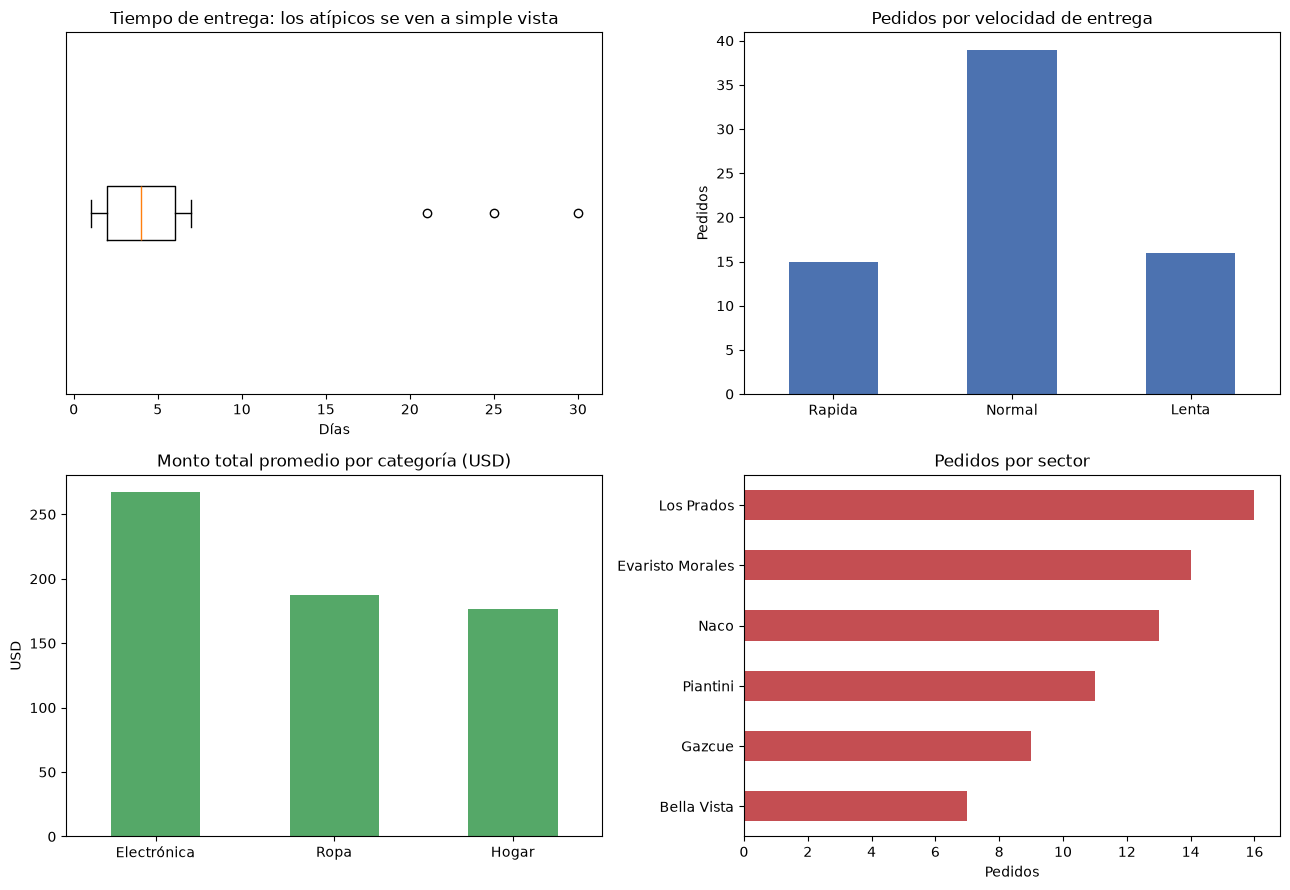

In [35]:
etiquetas_cat = {1: "Electrónica", 2: "Ropa", 3: "Hogar"}

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# (a) Atípicos en tiempo de entrega (datos originales, sin imputar)
axes[0, 0].boxplot(tiempos, vert=False)
axes[0, 0].set_title("Tiempo de entrega: los atípicos se ven a simple vista")
axes[0, 0].set_xlabel("Días")
axes[0, 0].set_yticks([])

# (b) Pedidos por velocidad de entrega
df["VelocidadEntrega"].value_counts().reindex(["Rapida", "Normal", "Lenta"]).plot.bar(
    ax=axes[0, 1], color="#4C72B0", rot=0)
axes[0, 1].set_title("Pedidos por velocidad de entrega")
axes[0, 1].set_xlabel("")
axes[0, 1].set_ylabel("Pedidos")

# (c) Monto promedio por categoría de producto
monto_cat = df.groupby("CategoriaProducto", observed=True)["MontoTotal"].mean()
monto_cat.index = monto_cat.index.astype(int).map(etiquetas_cat)
monto_cat.plot.bar(ax=axes[1, 0], color="#55A868", rot=0)
axes[1, 0].set_title("Monto total promedio por categoría (USD)")
axes[1, 0].set_xlabel("")
axes[1, 0].set_ylabel("USD")

# (d) Pedidos por sector
df["Sector"].value_counts().plot.barh(ax=axes[1, 1], color="#C44E52")
axes[1, 1].invert_yaxis()
axes[1, 1].set_title("Pedidos por sector")
axes[1, 1].set_xlabel("Pedidos")
axes[1, 1].set_ylabel("")

plt.tight_layout()
plt.show()

## 10. Resumen final y exportación

Verificamos el estado del DataFrame real (no escribimos nombres a mano) y guardamos el dataset limpio en `data/`.

In [36]:
nuevas = ["MontoTotal", "PedidoGrande", "Sector", "VelocidadEntrega"]

print("=" * 50)
print("RESUMEN FINAL DEL DATASET")
print("=" * 50)
print(f"Filas: {df.shape[0]}")
print(f"Columnas: {df.shape[1]}")
print("\nColumnas nuevas creadas:", [c for c in df.columns if c in nuevas])
print("Valores nulos restantes:", df.isnull().sum().sum())
df.head()

RESUMEN FINAL DEL DATASET
Filas: 70
Columnas: 12

Columnas nuevas creadas: ['MontoTotal', 'PedidoGrande', 'Sector', 'VelocidadEntrega']
Valores nulos restantes: 0


,PedidoID,Cliente,DireccionEnvio,CategoriaProducto,CantidadArticulos,PrecioUnitario,MetodoPago,TiempoEntregaDias,MontoTotal,PedidoGrande,Sector,VelocidadEntrega
0,38,Laura Ortiz,"Calle Beller #45, Los Prados",3,3,22.04,Transferencia,3.0,66.12,0,Los Prados,Normal
1,42,Luis Castillo,"Avenida 27 de Febrero #6, Evaristo Morales",2,4,71.95,Transferencia,4.0,287.80,1,Evaristo Morales,Normal
2,7,Joel Diaz,"Avenida Tiradentes #43, Naco",2,4,83.32,Tarjeta,4.0,333.28,1,Naco,Normal
3,61,Rafael Cruz,"Avenida 27 de Febrero #129, Naco",1,3,81.91,Efectivo,1.0,245.73,1,Naco,Rapida
4,3,Hector Mejia,"Calle Duarte #64, Los Prados",1,3,118.18,Efectivo,6.0,354.54,1,Los Prados,Lenta


In [37]:
RUTA_SALIDA = "../data/pedidos_ecommerce_limpio.csv"
df.to_csv(RUTA_SALIDA, index=False)
print(f"Archivo guardado como: {RUTA_SALIDA}")

Archivo guardado como: ../data/pedidos_ecommerce_limpio.csv


## 11. Conclusiones

- Se partió de **74 pedidos y 9 columnas** y se terminó con **70 pedidos y 12 columnas**, sin nulos.
- **Nulos:** `TiempoEntregaDias` se imputó con la mediana (hay atípicos de 21–30 días), `MetodoPago` con la moda y `ComentarioCliente` se descartó por tener más del 70 % de nulos.
- **Duplicados:** se eliminaron 4 filas repetidas.
- **Tipos:** `CategoriaProducto` pasó de `int64` a `category`, porque sus valores son etiquetas y no cantidades.
- **Features creadas:** `MontoTotal`, `PedidoGrande`, `Sector` y `VelocidadEntrega`.
- **Lección clave:** en `pd.cut` el último límite debe cubrir los valores extremos (`np.inf`); de lo contrario los atípicos se convierten silenciosamente en `NaN`.

**Siguientes pasos posibles:** analizar si el método de pago o el sector influyen en el tiempo de entrega, y estudiar qué distingue a los pedidos grandes.